In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt; plt.rc('font', size=16)
import matplotlib.cm as cm
import glob

from micom import load_pickle
from micom.qiime_formats import load_qiime_model_db, load_qiime_medium
from micom.workflows import grow, save_results, load_results
from micom.viz import *
from micom.measures import *
from micom.workflows.core import GrowthResults
from micom.viz.interactions import plot_focal_interactions
from micom.viz.interactions import plot_mes
from micom.interaction.scores import MES
from micom.interaction import interactions
from micom.interaction import summarize_interactions

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
taxa = ['B_caccae',
        'B_cellulosilyticus_WH2',
        'B_ovatus',
        'B_thetaiotaomicron',
        'B_uniformis',
        'B_vulgatus',
        'C_aerofaciens',
        'C_scindens',
        'C_spiroforme',
        # 'D_longicatena',
        'P_distasonis',
        'R_obeum'
        ]

pretty_names_dir = {'B_caccae': '$B. caccae$',
                'B_cellulosilyticus_WH2': '$B. cellulosilyticus$',
                'B_ovatus': '$B. ovatus$',
                'B_thetaiotaomicron': '$B. thetaiotaomicron$',
                'B_uniformis': '$B. uniformis$',
                'B_vulgatus': '$B. vulgatus$',
                'C_aerofaciens': '$C. aerofaciens$',
                'C_scindens': '$C. scindens$',
                'C_spiroforme': '$C. spiroforme$',
                # 'D_longicatena': '$D. longicatena$',
                'P_distasonis': '$P. distasonis$',
                'R_obeum': '$R. obeum$'
                }

abbr_names_dir = {'B_caccae': 'Bca',
                'B_cellulosilyticus_WH2': 'Bce',
                'B_ovatus': 'Bov',
                'B_thetaiotaomicron': 'Bth',
                'B_uniformis': 'Bun',
                'B_vulgatus': 'Bvu',
                'C_aerofaciens': 'Cae',
                'C_scindens': 'Csc',
                'C_spiroforme': 'Csp',
                # 'D_longicatena': 'Dlo',
                'P_distasonis': 'Pdi',
                'R_obeum': 'Rob'
                }

pretty_names = [pretty_names_dir[taxa] for taxa in taxa]

In [3]:
minimal_imports_lf0 = load_results("results/lf0/growth_minimal_imports_.zip")
minimal_imports_hf0 = load_results("results/hf0/growth_minimal_imports_.zip")

In [4]:
LF0 = ['mouse_01', 'mouse_02', 'mouse_03', 'mouse_04', 'mouse_05', 'mouse_06', 'mouse_07']
HF0 = ['mouse_08', 'mouse_09', 'mouse_10', 'mouse_11', 'mouse_12', 'mouse_13', 'mouse_14', 'mouse_15']

# Focal Interactions

In [5]:
# for taxa in minimal_imports_lf0[0].taxon.unique():
#     plot_focal_interactions(minimal_imports_lf0, taxa, f'results/lf0/interactions/interactions_{taxa}.html')
# for taxa in minimal_imports_hf0[0].taxon.unique():
#     plot_focal_interactions(minimal_imports_hf0, taxa, f'results/hf0/interactions/interactions_{taxa}.html')

In [6]:
interactions_lf0 = interactions(minimal_imports_lf0, taxa=None, threads=4)
interactions_lf0['diet'] = 'LF/HPP'
interactions_hf0 = interactions(minimal_imports_hf0, taxa=None, threads=4)
interactions_hf0['diet'] = 'HF/HS'
inters = pd.concat([interactions_lf0, interactions_hf0])
inters

,metabolite,focal,partner,class,flux,sample_id,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction,diet
0,ac[e],B_caccae,B_cellulosilyticus_WH2,provided,1.256192,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e),LF/HPP
1,ac[e],B_caccae,B_ovatus,provided,1.256192,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e),LF/HPP
2,ac[e],B_caccae,B_thetaiotaomicron,provided,0.048605,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e),LF/HPP
3,ac[e],B_caccae,B_vulgatus,provided,1.256192,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e),LF/HPP
4,ac[e],B_caccae,C_aerofaciens,provided,0.414848,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e),LF/HPP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2176,xan[e],R_obeum,C_spiroforme,co-consumed,0.000002,mouse_14,Xanthine,152.11086,5,4,HMDB00292,InChI=1S/C5H4N4O2/c10-4-2-3(7-1-6-2)8-5(11)9-4...,C00385,1188.0,EX_xan(e),HF/HS
2177,xan[e],R_obeum,C_aerofaciens,received,0.000007,mouse_14,Xanthine,152.11086,5,4,HMDB00292,InChI=1S/C5H4N4O2/c10-4-2-3(7-1-6-2)8-5(11)9-4...,C00385,1188.0,EX_xan(e),HF/HS
2178,gam[e],R_obeum,B_cellulosilyticus_WH2,received,0.000114,mouse_14,D-Glucosamine,180.17906,6,1,HMDB01514,NaN,C00329,439213.0,EX_gam(e),HF/HS
2179,gam[e],R_obeum,B_ovatus,received,0.000343,mouse_14,D-Glucosamine,180.17906,6,1,HMDB01514,NaN,C00329,439213.0,EX_gam(e),HF/HS


In [7]:
interactions_summary_lf0 = summarize_interactions(interactions_lf0)
interactions_summary_lf0['diet'] = 'LF/HPP'
interactions_summary_hf0 = summarize_interactions(interactions_hf0)
interactions_summary_hf0['diet'] = 'HF/HS'
inters_summary = pd.concat([interactions_summary_lf0, interactions_summary_hf0])
inters_summary['focal'] = inters_summary['focal'].map(abbr_names_dir)
inters_summary['partner'] = inters_summary['partner'].map(abbr_names_dir)
inters_summary

,sample_id,focal,partner,class,flux,mass_flux,C_flux,N_flux,n_ints,diet
0,mouse_01,Bca,Bce,co-consumed,5.933290,0.462987,15.665528,2.020762,5,LF/HPP
1,mouse_01,Bca,Bce,provided,23.274379,1.600686,50.198087,6.136919,8,LF/HPP
2,mouse_01,Bca,Bce,received,6.215618,0.112078,0.000417,0.000052,3,LF/HPP
3,mouse_01,Bca,Bov,co-consumed,9.739164,0.868299,29.248301,0.000000,2,LF/HPP
4,mouse_01,Bca,Bov,provided,4.588769,0.134390,2.516142,3.331328,4,LF/HPP
...,...,...,...,...,...,...,...,...,...,...
2609,mouse_15,Rob,Csp,co-consumed,0.087293,0.010385,0.349173,0.037411,7,HF/HS
2610,mouse_15,Rob,Csp,received,0.037411,0.002409,0.074823,0.012470,3,HF/HS
2611,mouse_15,Rob,Pdi,co-consumed,0.963619,0.017367,0.000247,0.000000,2,HF/HS
2612,mouse_15,Rob,Pdi,provided,8.038646,0.369480,12.632063,0.000061,4,HF/HS


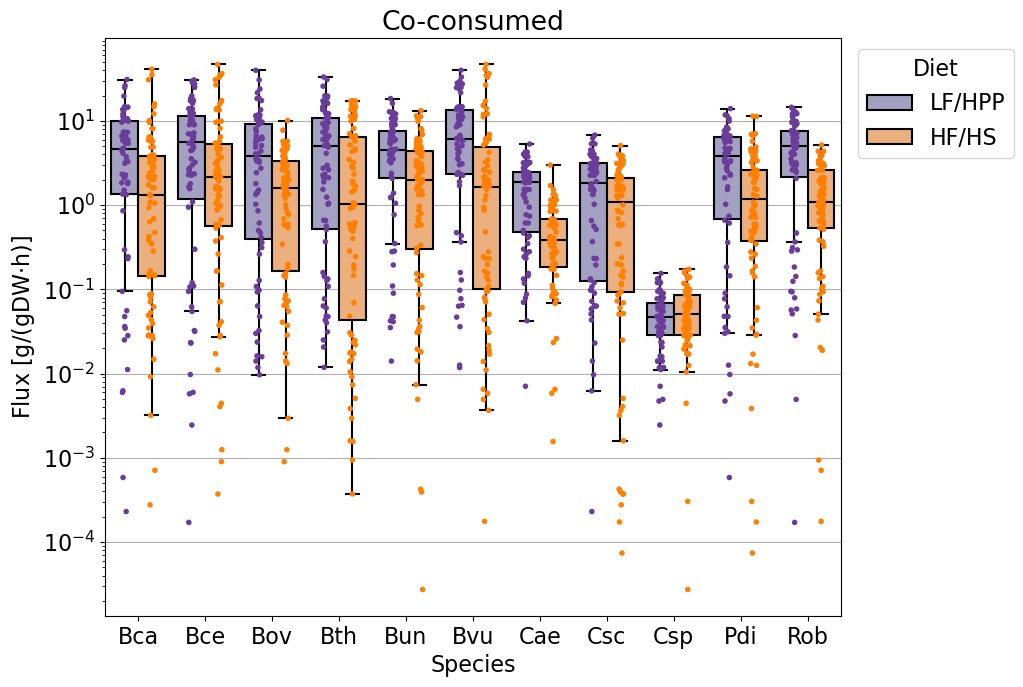

ANOVA
                 sum_sq      df          F        PR(>F)
diet         356.536490     1.0  72.353860  4.032353e-17
focal       1586.456624    10.0  32.194814  2.450089e-57
diet:focal    73.637275    10.0   1.494361  1.353128e-01
Residual    7972.982222  1618.0        NaN           NaN
Tukey HSD
0       group1      group2 meandiff   p-adj   lower   upper reject
51   HF/HS:Bov  LF/HPP:Bov   4.0645  0.0016  0.8061  7.3228   True
105  HF/HS:Bvu  LF/HPP:Bvu   4.1814  0.0008  0.9385  7.4244   True
175  HF/HS:Rob  LF/HPP:Rob    3.691  0.0075  0.4673  6.9147   True


In [8]:
dat = inters_summary[inters_summary['class']=='co-consumed'].copy()
plt.figure(figsize=(9.5, 7.5))
sns.stripplot(
    data=dat, 
    x='focal', 
    y='flux', 
    hue='diet', 
    log_scale=True,
    size=4,
    # palette=[cm.tab20c(5), cm.tab20c(13)],
    palette=[cm.Paired(9), cm.Paired(7)],
    dodge=True,
    alpha=1,
    legend=False
    )
sns.boxplot(
    data=dat, 
    x='focal', 
    y='flux', 
    hue='diet', 
    log_scale=True,
    saturation=0.75,
    # palette=[cm.Paired(7), cm.Paired(9)],
    palette=[cm.tab20c(13), cm.tab20c(6)],
    showfliers=False,
    # width=0.8,
    linewidth=1.5,
    linecolor='black'
    )
plt.legend(loc='upper right', title='Diet', bbox_to_anchor=(1.25, 1))
plt.xlabel('Species')
plt.ylabel('Flux [g/(gDW$\cdot$h)]')
plt.title('Co-consumed')
plt.grid(axis='y')
plt.savefig('results/interactions_coconsumption.svg', dpi=300, bbox_inches='tight')
plt.show()

model = ols('np.log(flux) ~ diet + focal + diet:focal', data=dat).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print('ANOVA')
print(anova_table)

tukey_results = pairwise_tukeyhsd(dat['flux'].values, dat['diet'].astype(str) + ":" + dat['focal'].astype(str).values)
tukey_df = pd.DataFrame(tukey_results.summary().data)
tukey_df.columns = tukey_df.iloc[0]
tukey_df = tukey_df.drop(0)
tukey_df = tukey_df.reset_index(drop=True)
tukey_df['g1_diet'] = tukey_df['group1'].str.split(':').str[0].values
tukey_df['g2_diet'] = tukey_df['group2'].str.split(':').str[0].values
tukey_df['g1_focal'] = tukey_df['group1'].str.split(':').str[1].values
tukey_df['g2_focal'] = tukey_df['group2'].str.split(':').str[1].values
tukey_df_sig = tukey_df[(tukey_df['reject']==True) & (tukey_df['g1_focal'] == tukey_df['g2_focal'])]
tukey_df_sig = tukey_df_sig.loc[:, ['group1', 'group2', 'meandiff', 'p-adj', 'lower', 'upper', 'reject']]
print('Tukey HSD')
print(tukey_df_sig)

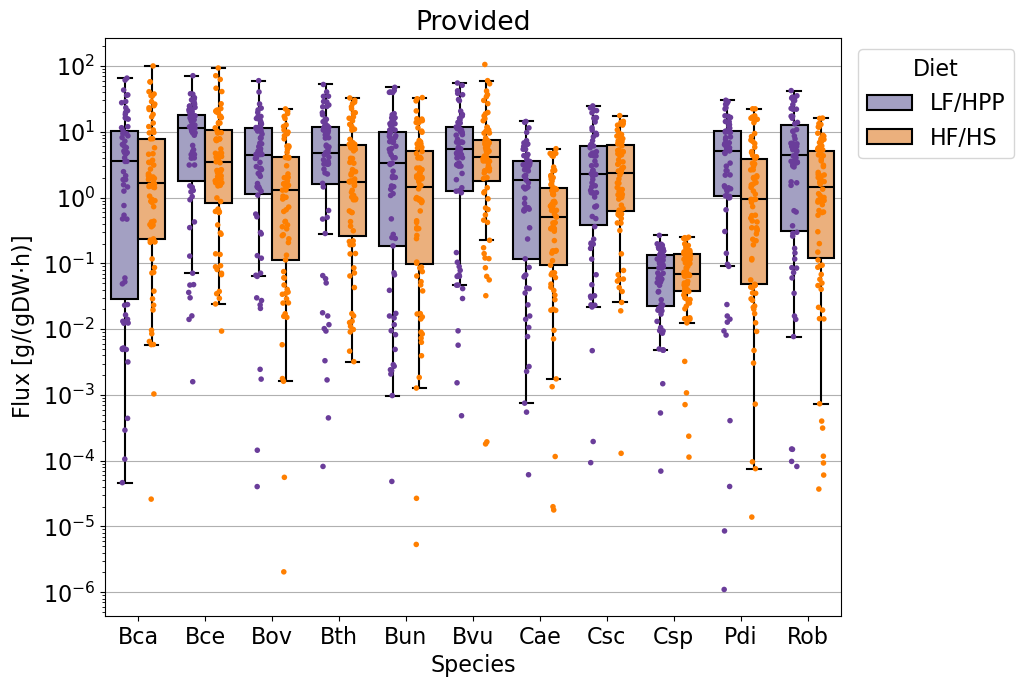

ANOVA
                  sum_sq      df          F        PR(>F)
diet           81.136997     1.0  11.023129  9.199843e-04
focal        1783.788843    10.0  24.234240  5.205407e-43
diet:focal    117.684018    10.0   1.598834  1.011060e-01
Residual    11821.146144  1606.0        NaN           NaN
Tukey HSD
Empty DataFrame
Columns: [group1, group2, meandiff, p-adj, lower, upper, reject]
Index: []


In [9]:
dat = inters_summary[inters_summary['class']=='provided'].copy()
plt.figure(figsize=(9.5, 7.5))
sns.stripplot(
    data=dat, 
    x='focal', 
    y='flux', 
    hue='diet', 
    log_scale=True,
    size=4,
    # palette=[cm.tab20c(5), cm.tab20c(13)],
    palette=[cm.Paired(9), cm.Paired(7)],
    dodge=True,
    alpha=1,
    legend=False
    )
sns.boxplot(
    data=dat, 
    x='focal', 
    y='flux', 
    hue='diet', 
    log_scale=True,
    saturation=0.75,
    # palette=[cm.Paired(7), cm.Paired(9)],
    palette=[cm.tab20c(13), cm.tab20c(6)],
    showfliers=False,
    # width=0.8,
    linewidth=1.5,
    linecolor='black'
    )
plt.legend(loc='upper right', title='Diet', bbox_to_anchor=(1.25, 1))
plt.xlabel('Species')
plt.ylabel('Flux [g/(gDW$\cdot$h)]')
plt.title('Provided')
plt.grid(axis='y')
plt.savefig('results/interactions_provided.svg', dpi=300, bbox_inches='tight')
plt.show()

model = ols('np.log(flux) ~ diet + focal + diet:focal', data=dat).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print('ANOVA')
print(anova_table)

tukey_results = pairwise_tukeyhsd(dat['flux'].values, dat['diet'].astype(str) + ":" + dat['focal'].astype(str).values)
tukey_df = pd.DataFrame(tukey_results.summary().data)
tukey_df.columns = tukey_df.iloc[0]
tukey_df = tukey_df.drop(0)
tukey_df = tukey_df.reset_index(drop=True)
tukey_df['g1_diet'] = tukey_df['group1'].str.split(':').str[0].values
tukey_df['g2_diet'] = tukey_df['group2'].str.split(':').str[0].values
tukey_df['g1_focal'] = tukey_df['group1'].str.split(':').str[1].values
tukey_df['g2_focal'] = tukey_df['group2'].str.split(':').str[1].values
tukey_df_sig = tukey_df[(tukey_df['reject']==True) & (tukey_df['g1_focal'] == tukey_df['g2_focal'])]
tukey_df_sig = tukey_df_sig.loc[:, ['group1', 'group2', 'meandiff', 'p-adj', 'lower', 'upper', 'reject']]
print('Tukey HSD')
print(tukey_df_sig)

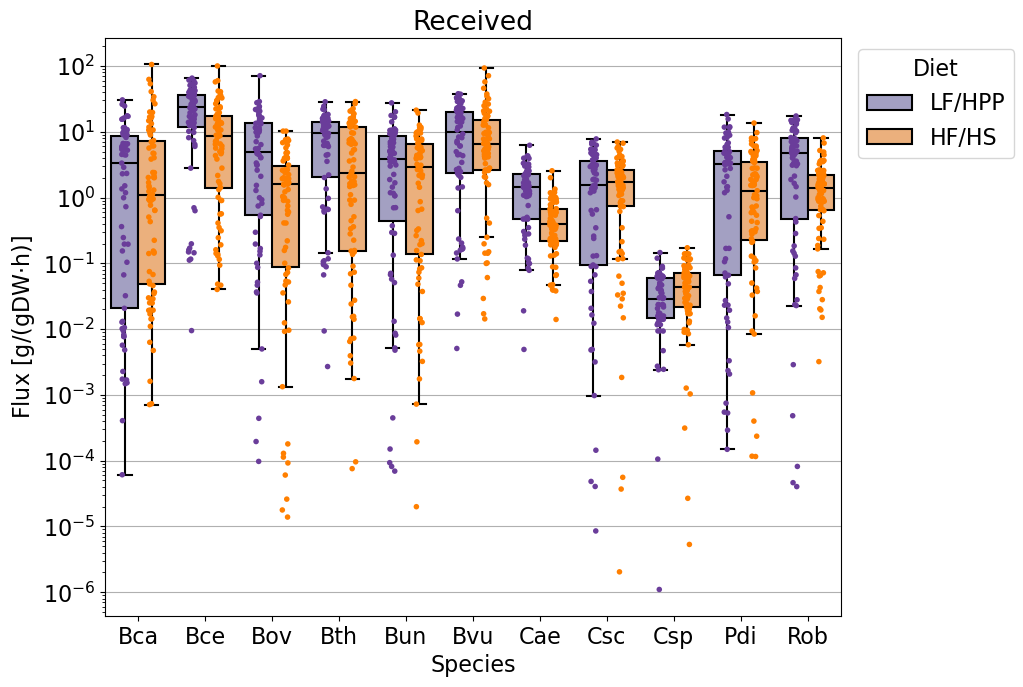

ANOVA
                  sum_sq      df          F        PR(>F)
diet           77.536235     1.0  11.860607  5.880758e-04
focal        3039.213410    10.0  46.490411  9.852719e-82
diet:focal    184.516394    10.0   2.822521  1.772535e-03
Residual    10498.889200  1606.0        NaN           NaN
Tukey HSD
0      group1      group2 meandiff   p-adj   lower    upper reject
31  HF/HS:Bce  LF/HPP:Bce  11.3324     0.0  6.2722  16.3926   True
51  HF/HS:Bov  LF/HPP:Bov   6.4766  0.0011  1.3668  11.5864   True


In [10]:
dat = inters_summary[inters_summary['class']=='received'].copy()
plt.figure(figsize=(9.5, 7.5))
sns.stripplot(
    data=dat, 
    x='focal', 
    y='flux', 
    hue='diet', 
    log_scale=True,
    size=4,
    # palette=[cm.tab20c(5), cm.tab20c(13)],
    palette=[cm.Paired(9), cm.Paired(7)],
    dodge=True,
    alpha=1,
    legend=False
    )
sns.boxplot(
    data=dat, 
    x='focal', 
    y='flux', 
    hue='diet', 
    log_scale=True,
    saturation=0.75,
    # palette=[cm.Paired(7), cm.Paired(9)],
    palette=[cm.tab20c(13), cm.tab20c(6)],
    showfliers=False,
    # width=0.8,
    linewidth=1.5,
    linecolor='black'
    )
plt.legend(loc='upper right', title='Diet', bbox_to_anchor=(1.25, 1))
plt.xlabel('Species')
plt.ylabel('Flux [g/(gDW$\cdot$h)]')
plt.title('Received')
plt.grid(axis='y')
plt.savefig('results/interactions_received.svg', dpi=300, bbox_inches='tight')
plt.show()

model = ols('np.log(flux) ~ diet + focal + diet:focal', data=dat).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print('ANOVA')
print(anova_table)

tukey_results = pairwise_tukeyhsd(dat['flux'].values, dat['diet'].astype(str) + ":" + dat['focal'].astype(str).values)
tukey_df = pd.DataFrame(tukey_results.summary().data)
tukey_df.columns = tukey_df.iloc[0]
tukey_df = tukey_df.drop(0)
tukey_df = tukey_df.reset_index(drop=True)
tukey_df['g1_diet'] = tukey_df['group1'].str.split(':').str[0].values
tukey_df['g2_diet'] = tukey_df['group2'].str.split(':').str[0].values
tukey_df['g1_focal'] = tukey_df['group1'].str.split(':').str[1].values
tukey_df['g2_focal'] = tukey_df['group2'].str.split(':').str[1].values
tukey_df_sig = tukey_df[(tukey_df['reject']==True) & (tukey_df['g1_focal'] == tukey_df['g2_focal'])]
tukey_df_sig = tukey_df_sig.loc[:, ['group1', 'group2', 'meandiff', 'p-adj', 'lower', 'upper', 'reject']]
print('Tukey HSD')
print(tukey_df_sig)

In [11]:
inters_summary. \
    groupby(['focal', 
             'sample_id', 
             'diet'])['partner'] \
        .count() \
            .groupby(['focal', 
                      'diet']) \
                .mean() \
                    .unstack()

diet,HF/HS,LF/HPP
focal,,
Bca,30.000,29.142857
Bce,30.000,30.000000
Bov,29.250,29.571429
Bth,29.875,29.714286
Bun,29.625,29.714286
Bvu,29.750,29.857143
Cae,29.625,29.571429
Csc,29.875,29.428571
Csp,29.250,29.428571


# MES

In [12]:
growth_lf0 = minimal_imports_lf0.growth_rates
growth_lf0['diet'] = 'LF/HPP'
growth_hf0 = minimal_imports_hf0.growth_rates
growth_hf0['diet'] = 'HF/HS'
growth = pd.concat([growth_lf0, growth_hf0], axis=0, ignore_index=True)
phenotype = pd.DataFrame({
    'sample_id':growth.sample_id,
    'diet':growth.diet
    })
phenotype.drop_duplicates(subset='sample_id', inplace=True)
phenotype.set_index('sample_id', inplace=True)
growth

,abundance,growth_rate,reactions,metabolites,taxon,tradeoff,sample_id,diet
0,0.097084,1.231692e-14,2381,1461,B_caccae,0.6,mouse_01,LF/HPP
1,0.444060,3.826183e-02,2779,1702,B_cellulosilyticus_WH2,0.6,mouse_01,LF/HPP
2,0.139322,1.136146e-22,2476,1526,B_ovatus,0.6,mouse_01,LF/HPP
3,0.093460,1.196529e-01,2524,1549,B_thetaiotaomicron,0.6,mouse_01,LF/HPP
4,0.035084,1.535031e-22,2418,1500,B_uniformis,0.6,mouse_01,LF/HPP
...,...,...,...,...,...,...,...,...
160,0.004272,1.445010e-06,920,850,C_aerofaciens,0.6,mouse_15,HF/HS
161,0.019892,4.351062e-07,2049,1394,C_scindens,0.6,mouse_15,HF/HS
162,0.000125,2.261928e-04,1980,1313,C_spiroforme,0.6,mouse_15,HF/HS
163,0.034353,9.585099e-03,2519,1570,P_distasonis,0.6,mouse_15,HF/HS


In [13]:
phenotype

,diet
sample_id,
mouse_01,LF/HPP
mouse_02,LF/HPP
mouse_03,LF/HPP
mouse_04,LF/HPP
mouse_05,LF/HPP
mouse_06,LF/HPP
mouse_07,LF/HPP
mouse_08,HF/HS
mouse_09,HF/HS


In [14]:
exchanges_lf0 = minimal_imports_lf0.exchanges
growth_lf0['diet'] = 'LF/HPP'
exchanges_hf0 = minimal_imports_hf0.exchanges
growth_hf0['diet'] = 'HF/HS'
exchanges = pd.concat([exchanges_lf0, exchanges_hf0], axis=0, ignore_index=True)
exchanges

,taxon,sample_id,tolerance,reaction,flux,abundance,metabolite,direction
0,medium,mouse_01,0.000001,EX_cys_L_m,-0.005313,NaN,cys_L_m,import
1,medium,mouse_01,0.000001,EX_cu2_m,-0.000200,NaN,cu2_m,import
2,medium,mouse_01,0.000001,EX_hspg_m,-0.000114,NaN,hspg_m,import
3,medium,mouse_01,0.000001,EX_k_m,-0.000200,NaN,k_m,import
4,medium,mouse_01,0.000001,EX_ttdca_m,0.000521,NaN,ttdca_m,export
...,...,...,...,...,...,...,...,...
8422,R_obeum,mouse_15,0.000001,EX_gln_L(e),22.185849,0.009636,gln_L[e],export
8423,R_obeum,mouse_15,0.000001,EX_val_L(e),-0.000001,0.009636,val_L[e],import
8424,R_obeum,mouse_15,0.000001,EX_fum(e),177.730535,0.009636,fum[e],export
8425,R_obeum,mouse_15,0.000001,EX_nh4(e),233.377499,0.009636,nh4[e],export


In [15]:
annotations = minimal_imports_lf0.annotations
annotations

,metabolite,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction
0,12ppd_S[e],"(S)-propane-1,2-diol",76.09442,3,0,HMDB06213,"InChI=1S/C3H8O2/c1-3(5)2-4/h3-5H,2H2,1H3/t3-/m...",C02917,NaN,EX_12ppd_S(e)
1,2obut[e],2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e)
2,4abut[e],4-Aminobutanoate,103.11976,4,1,HMDB00112,"InChI=1S/C4H9NO2/c5-3-1-2-4(6)7/h1-3,5H2,(H,6,7)",C00334,119.0,EX_4abut(e)
3,4hbz[e],4-hydroxybenzoate,137.11280,7,0,HMDB00500,"InChI=1S/C7H6O3/c8-6-3-1-5(2-4-6)7(9)10/h1-4,8...",C00156,NaN,EX_4hbz(e)
4,MGlcn10[e],mucin-type O-glycan No 10,NaN,44,4,NaN,NaN,NaN,NaN,EX_MGlcn10(e)
...,...,...,...,...,...,...,...,...,...,...
1399,mqn7_m,Menaquinone 7,648.99916,46,0,NaN,NaN,C00828,4086.0,EX_mqn7_m
1400,n2_m,Nitrogen,28.01340,0,2,NaN,NaN,NaN,NaN,EX_n2_m
1401,sbt_D_m,D-glucitol,182.17176,6,0,HMDB00247,InChI=1S/C6H14O6/c7-1-3(9)5(11)6(12)4(10)2-8/h...,C00794,5780.0,EX_sbt_D_m
1402,thm_m,Thiamin,265.35458,12,4,HMDB00235,InChI=1S/C12H17N4OS/c1-8-11(3-4-17)18-7-16(8)6...,C00378,1130.0,EX_thm_m


In [16]:
minimal_imports = GrowthResults(growth, exchanges, annotations)
print(minimal_imports)

GrowthResults(growth_rates=     abundance   growth_rate  reactions  metabolites                   taxon  \
0     0.097084  1.231692e-14       2381         1461                B_caccae   
1     0.444060  3.826183e-02       2779         1702  B_cellulosilyticus_WH2   
2     0.139322  1.136146e-22       2476         1526                B_ovatus   
3     0.093460  1.196529e-01       2524         1549      B_thetaiotaomicron   
4     0.035084  1.535031e-22       2418         1500             B_uniformis   
..         ...           ...        ...          ...                     ...   
160   0.004272  1.445010e-06        920          850           C_aerofaciens   
161   0.019892  4.351062e-07       2049         1394              C_scindens   
162   0.000125  2.261928e-04       1980         1313            C_spiroforme   
163   0.034353  9.585099e-03       2519         1570            P_distasonis   
164   0.009636  5.057161e-06       1225         1088                 R_obeum   

     tradeof

In [17]:
# plot_mes(minimal_imports, 'results/mes.html', phenotype.diet)

In [18]:
scores = MES(minimal_imports)
def define_diet(sample_id):
    return 'LF/HPP' if sample_id in LF0 else 'HF/HS'
scores['diet'] = scores.sample_id.apply(define_diet)
scores

,metabolite,sample_id,MES,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction,diet
0,12dhchol[e],mouse_01,1.0,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
1,12dhchol[e],mouse_02,1.0,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
2,12dhchol[e],mouse_03,1.0,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
3,12dhchol[e],mouse_04,1.0,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
4,12dhchol[e],mouse_05,1.0,12-Dehydrocholate,405.54758,24,0,NaN,NaN,NaN,NaN,EX_12dhchol(e),LF/HPP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1579,zn2[e],mouse_11,0.0,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e),HF/HS
1580,zn2[e],mouse_12,0.0,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e),HF/HS
1581,zn2[e],mouse_13,0.0,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e),HF/HS
1582,zn2[e],mouse_14,0.0,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e),HF/HS
